# *Definicion del problema* 

- *Dataset usado:* [ImpactOfSocialMediaOnLife - Kaggle](https://www.kaggle.com/datasets/harishyadav0506/impact-of-social-media-on-life/data)  
- *Problema:* Los estudiantes hoy en dia usan mucho las redes sociales (yo incluido), mi intencion con este proyecto es segun el dataset escogido con 4500 registros y 16 columnas, poder predecir si un estudiante va a tener un impacto Negativo, Neutro o Positivo de su uso. El impacto se calcula en base a diferentes campos como: rendimiento academico (*Academic_Performance_GPA*) , calidad del sueno (*Sleep_Quality_Score*) y horas de este mismo (*Sleep_Duration_Hours*) ademas de media de horas diarias de uso (*Daily_Usage_Hours*), horas extra de uso en fin de semana (*Weekend_Extra_Hours*) y indice de salud mental (*Mental_Health_Index*)  
- *Aplicación real:* Herramienta de detección temprana para orientadores escolares, universidades o psicólogos que permita identificar a estudiantes en riesgo por abuso de redes sociales antes de que caigan sus notas o su salud mental.  
- *Tipo de problema:* Clasificación multiclase.
- *Variable Objetivo:* y = 'Overall_Impact'  

In [25]:
# Importacion de librerias 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 

# Lectura inicial del archivo csv
df = pd.read_csv('Social_media_impact_on_life.csv')

#df.info()
print(f"Nulos: \n{df.isnull().sum()}")
df.describe()

Nulos: 
Student_ID                      0
Age                             0
Gender                          0
Academic_Level                  0
Primary_Platform                0
Daily_Usage_Hours               0
Weekend_Extra_Hours             0
Device_Type                     0
Sleep_Duration_Hours            0
Sleep_Quality_Score             0
Late_Night_Usage                0
Social_Comparison_Frequency     0
Perceived_Stress_Score         46
Mental_Health_Index             0
Academic_Performance_GPA       85
Overall_Impact                  0
dtype: int64


,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
count,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4454.000000,4500.000000,4415.000000
mean,18.703333,5.295933,1.796844,6.701333,2.472000,13.512124,79.873111,3.429282
std,1.981182,2.604497,0.699245,1.189998,1.030484,7.072859,12.876044,0.392662
min,15.000000,0.900000,0.000000,3.000000,1.000000,0.000000,32.000000,1.900000
25%,17.000000,3.400000,1.300000,6.000000,2.000000,9.000000,72.000000,3.200000
50%,19.000000,4.700000,1.800000,6.800000,3.000000,13.000000,82.000000,3.460000
75%,20.000000,6.600000,2.300000,7.500000,3.000000,18.000000,89.000000,3.720000
max,26.000000,14.000000,4.500000,10.500000,5.000000,40.000000,98.000000,4.000000


# Flujo de trabajo : 

- *1. Rellenado de nulos:* 
  - *Academic_Performance_GPA* tiene 85 valores nulos, en este caso, se va a rellenar con la media agrupada por cada nivel educativo, es decir, los nulos de por ejemplo  "High School" se separaran de los niveles educativos distintos.
  - *Perceived_Stress_Score* tiene 46 valores nulos, se va a rellenar con la media agrupada por cada nivel educativo al igual que el campo anterior, ya que intuyo que el nivel de estres recivido por un estudiante de carrera no es el mismo que uno de instituto.

- *2. Eliminacion de campos:*
  - En este caso, el campo "Student_ID" es irrelevante, por lo cual se elimina. 

In [26]:
# Rellenado de nulos segun nivel educativo
df['Academic_Performance_GPA'] = df['Academic_Performance_GPA'].fillna(
    df.groupby('Academic_Level')['Academic_Performance_GPA'].transform('median'))

df['Perceived_Stress_Score'] = df['Perceived_Stress_Score'].fillna(
    df.groupby('Academic_Level')['Perceived_Stress_Score'].transform('median'))


# Borrado de "Student_ID"
df = df.drop(columns='Student_ID')

# Se imprime el dataset para verificar cambios.
display(df.head())
print(f"Nulos: \n{df.isnull().sum()}")

,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


Nulos: 
Age                            0
Gender                         0
Academic_Level                 0
Primary_Platform               0
Daily_Usage_Hours              0
Weekend_Extra_Hours            0
Device_Type                    0
Sleep_Duration_Hours           0
Sleep_Quality_Score            0
Late_Night_Usage               0
Social_Comparison_Frequency    0
Perceived_Stress_Score         0
Mental_Health_Index            0
Academic_Performance_GPA       0
Overall_Impact                 0
dtype: int64


# *EDA (Analisis de datos exploratorio) Preguntas.*

1. *Son equilibrados nuestros datos, o estan desbalanceados?*
2. *Los alumnos con peor tiempo y calidad de suenio, tienen un reendimiento academico peor ?*
3. *Los alumnos con peor tiempo y calidad de suenio, tienen un mayor uso de redes sociales ?*
4. *Tiene relacion la edad, con las horas de uso de redes sociales?*
5. *Importa el tipo de red social que mas usa cada alumno, o son todas igual de perjudiciales?*
6. *Mapa de calor (Correlacion de variables)*

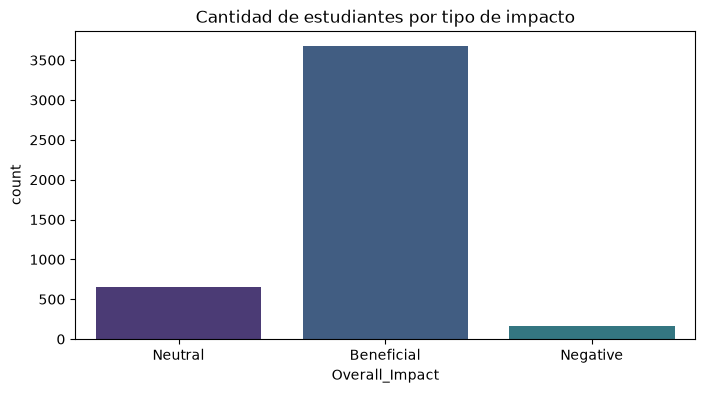

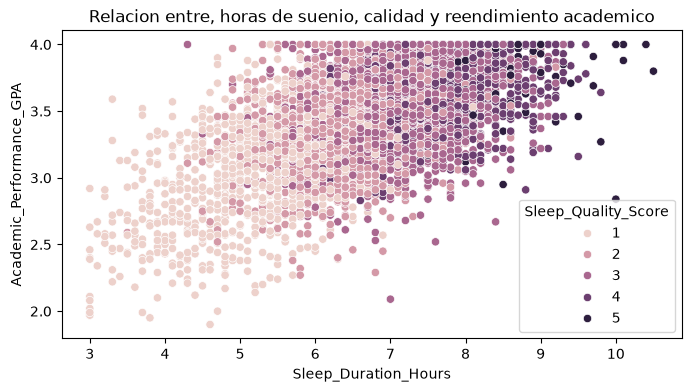

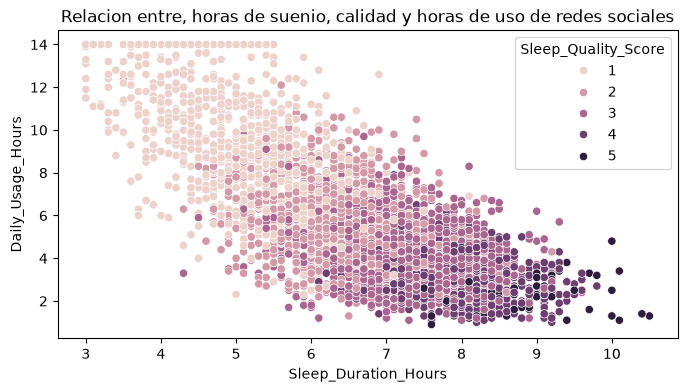

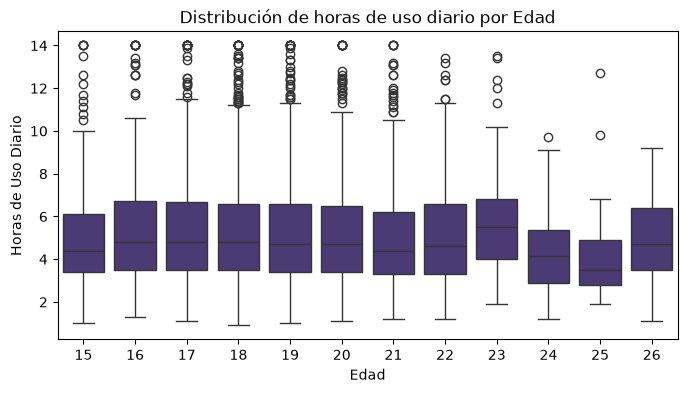

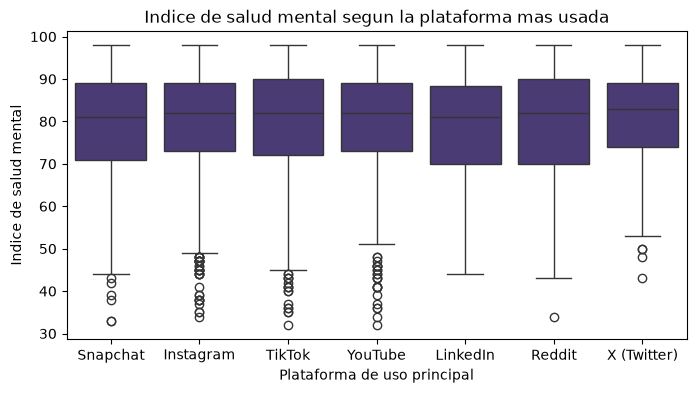

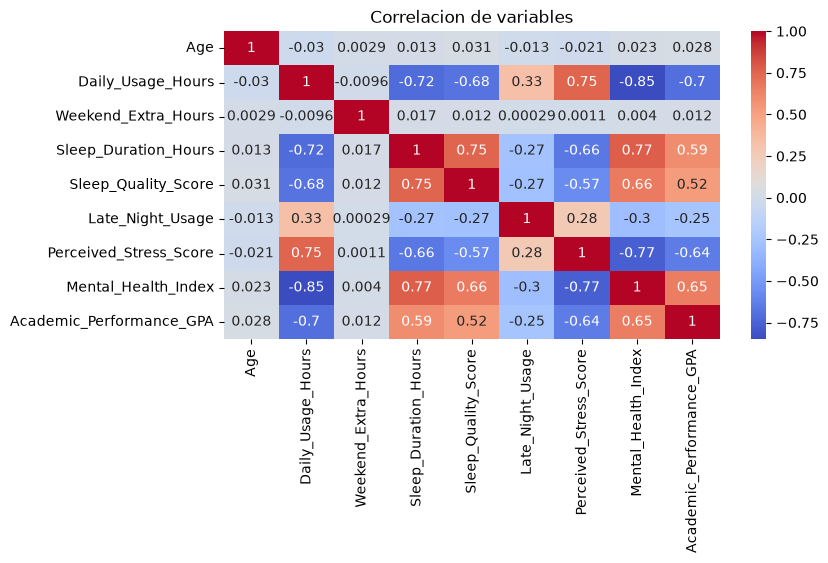

In [ ]:
# Configuracion de paleta de colores de seaborn
sns.set_palette('viridis')

# 1. 
plt.figure(figsize=(8,4))
sns.countplot(df,x='Overall_Impact',hue='Overall_Impact')
plt.title('Cantidad de estudiantes por tipo de impacto')
plt.show()

# 2.
plt.figure(figsize=(8,4))
sns.scatterplot(df,x='Sleep_Duration_Hours', y='Academic_Performance_GPA', hue='Sleep_Quality_Score')
plt.title('Relacion entre, horas de suenio, calidad y reendimiento academico')
plt.show()

# 3.
plt.figure(figsize=(8,4))
sns.scatterplot(df,x='Sleep_Duration_Hours', y='Daily_Usage_Hours', hue='Sleep_Quality_Score')
plt.title('Relacion entre, horas de suenio, calidad y horas de uso de redes sociales')
plt.show()

# 4. 
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='Age', y='Daily_Usage_Hours')
plt.title('Distribución de horas de uso diario por Edad')
plt.xlabel('Edad')
plt.ylabel('Horas de Uso Diario')
plt.show()

# 5.
plt.figure(figsize=(8,4))
sns.boxplot(df, x='Primary_Platform', y='Mental_Health_Index')
plt.title('Indice de salud mental segun la plataforma mas usada')
plt.xlabel('Plataforma de uso principal')
plt.ylabel('Indice de salud mental')
plt.show()

# 6. Ahi que mapear variables categoricas a numericas para un mapa de calor mas completo.
plt.figure(figsize=(8,4))
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', annot=True)
plt.title('Correlacion de variables')
plt.show()

# *EDA (Analisis de datos exploratorio) Respuestas.*

1. *Como podemos ver en el primer grafico, hay muchisimos mas estudiantes con un impacto beneficial que estudiantes con un impacto neutro o negativo, por lo cual nuestros datos estan desbalanceados y puede perjudicar a nuestro modelo.*
2. *En el segundo grafico, vemos como a medida que las horas de sueno y la calidad aumentan, progresivamente aumenta el indice GPA de cada alumno, aunque eso no quita que haya alumnos prodijio que con 3 horas de suenio y una calidad baja del mismo, tengan un indice GPA superior al resto de alumnos con mismas horas y calidad de suenio. Para el entrenamiento del modelo, se usara una variable que es el resultado de la multiplicacion de horas de suenio x calidad de suenio.*
3. *Como vemos en el tercer grafico, a medida que bajan las horas diarias de uso (sin contar horas extra en fin de semana) no solo aumentan las horas de suenio si no que aumenta la calidad del mismo.*
4. *En el cuarto grafico, vemos que en el caso de los estudiantes, no tiene relacion la edad con las horas diarias que usan las redes sociales.*
5. *Al ver el quinto grafico, podemos ver dos cosas: la primera es que como tal , la mediana de indice de salud mental no varia segun el tipo de red social que mas usa el estudiante promedio, sin embargo, lo segundo que vemos es que redes sociales como Instagram/TikTok/Youtube, tienen una concentracion de valores atipicos muy inferiores al resto, por lo que respecto a la pregunta si importa la red social principal, si, si importa ya que es mas probable tener una peor salud mental en TikTok que en Linkedin aunque la mediana sea parecida.*